

---



---


# Multi-class Semantic Segmentation on the PanNuke Histological Dataset
---



---



## % Libraries - Imports

In [1]:
import os
import random

import numpy as np

import matplotlib.pyplot as plt

## % Mount Google drive

In [ ]:
# mount Google Drive when running on Colab, otherwise use the local project folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = "/content/drive/MyDrive/Colab Notebooks/Deep_learning_course/Final_project/PanNuke"
except ImportError:
    PROJECT_DIR = os.getcwd()   # running locally, from the project folder

print("PROJECT_DIR:", PROJECT_DIR)

### --- Load data - PanNuke dataset - Fold1 ---
PanNuke Dataset for Nuclei Instance Segmentation and Classification - https://huggingface.co/datasets/RationAI/PanNuke

In [3]:
# load the PanNuke Fold1 images and their per-category instance masks
images = np.load(PROJECT_DIR + "/data_root/images.npy")
masks = np.load(PROJECT_DIR + "/data_root/masks.npy")

# sanity-check the loaded array shapes and dtypes
print("images shape:", images.shape, "images dtype:", images.dtype)
print("masks shape:", masks.shape, "masks dtype:", masks.dtype)

images shape: (2656, 256, 256, 3) images dtype: float64
masks shape: (2656, 256, 256, 6) masks dtype: float64


### --- Data exploration and visualization ---

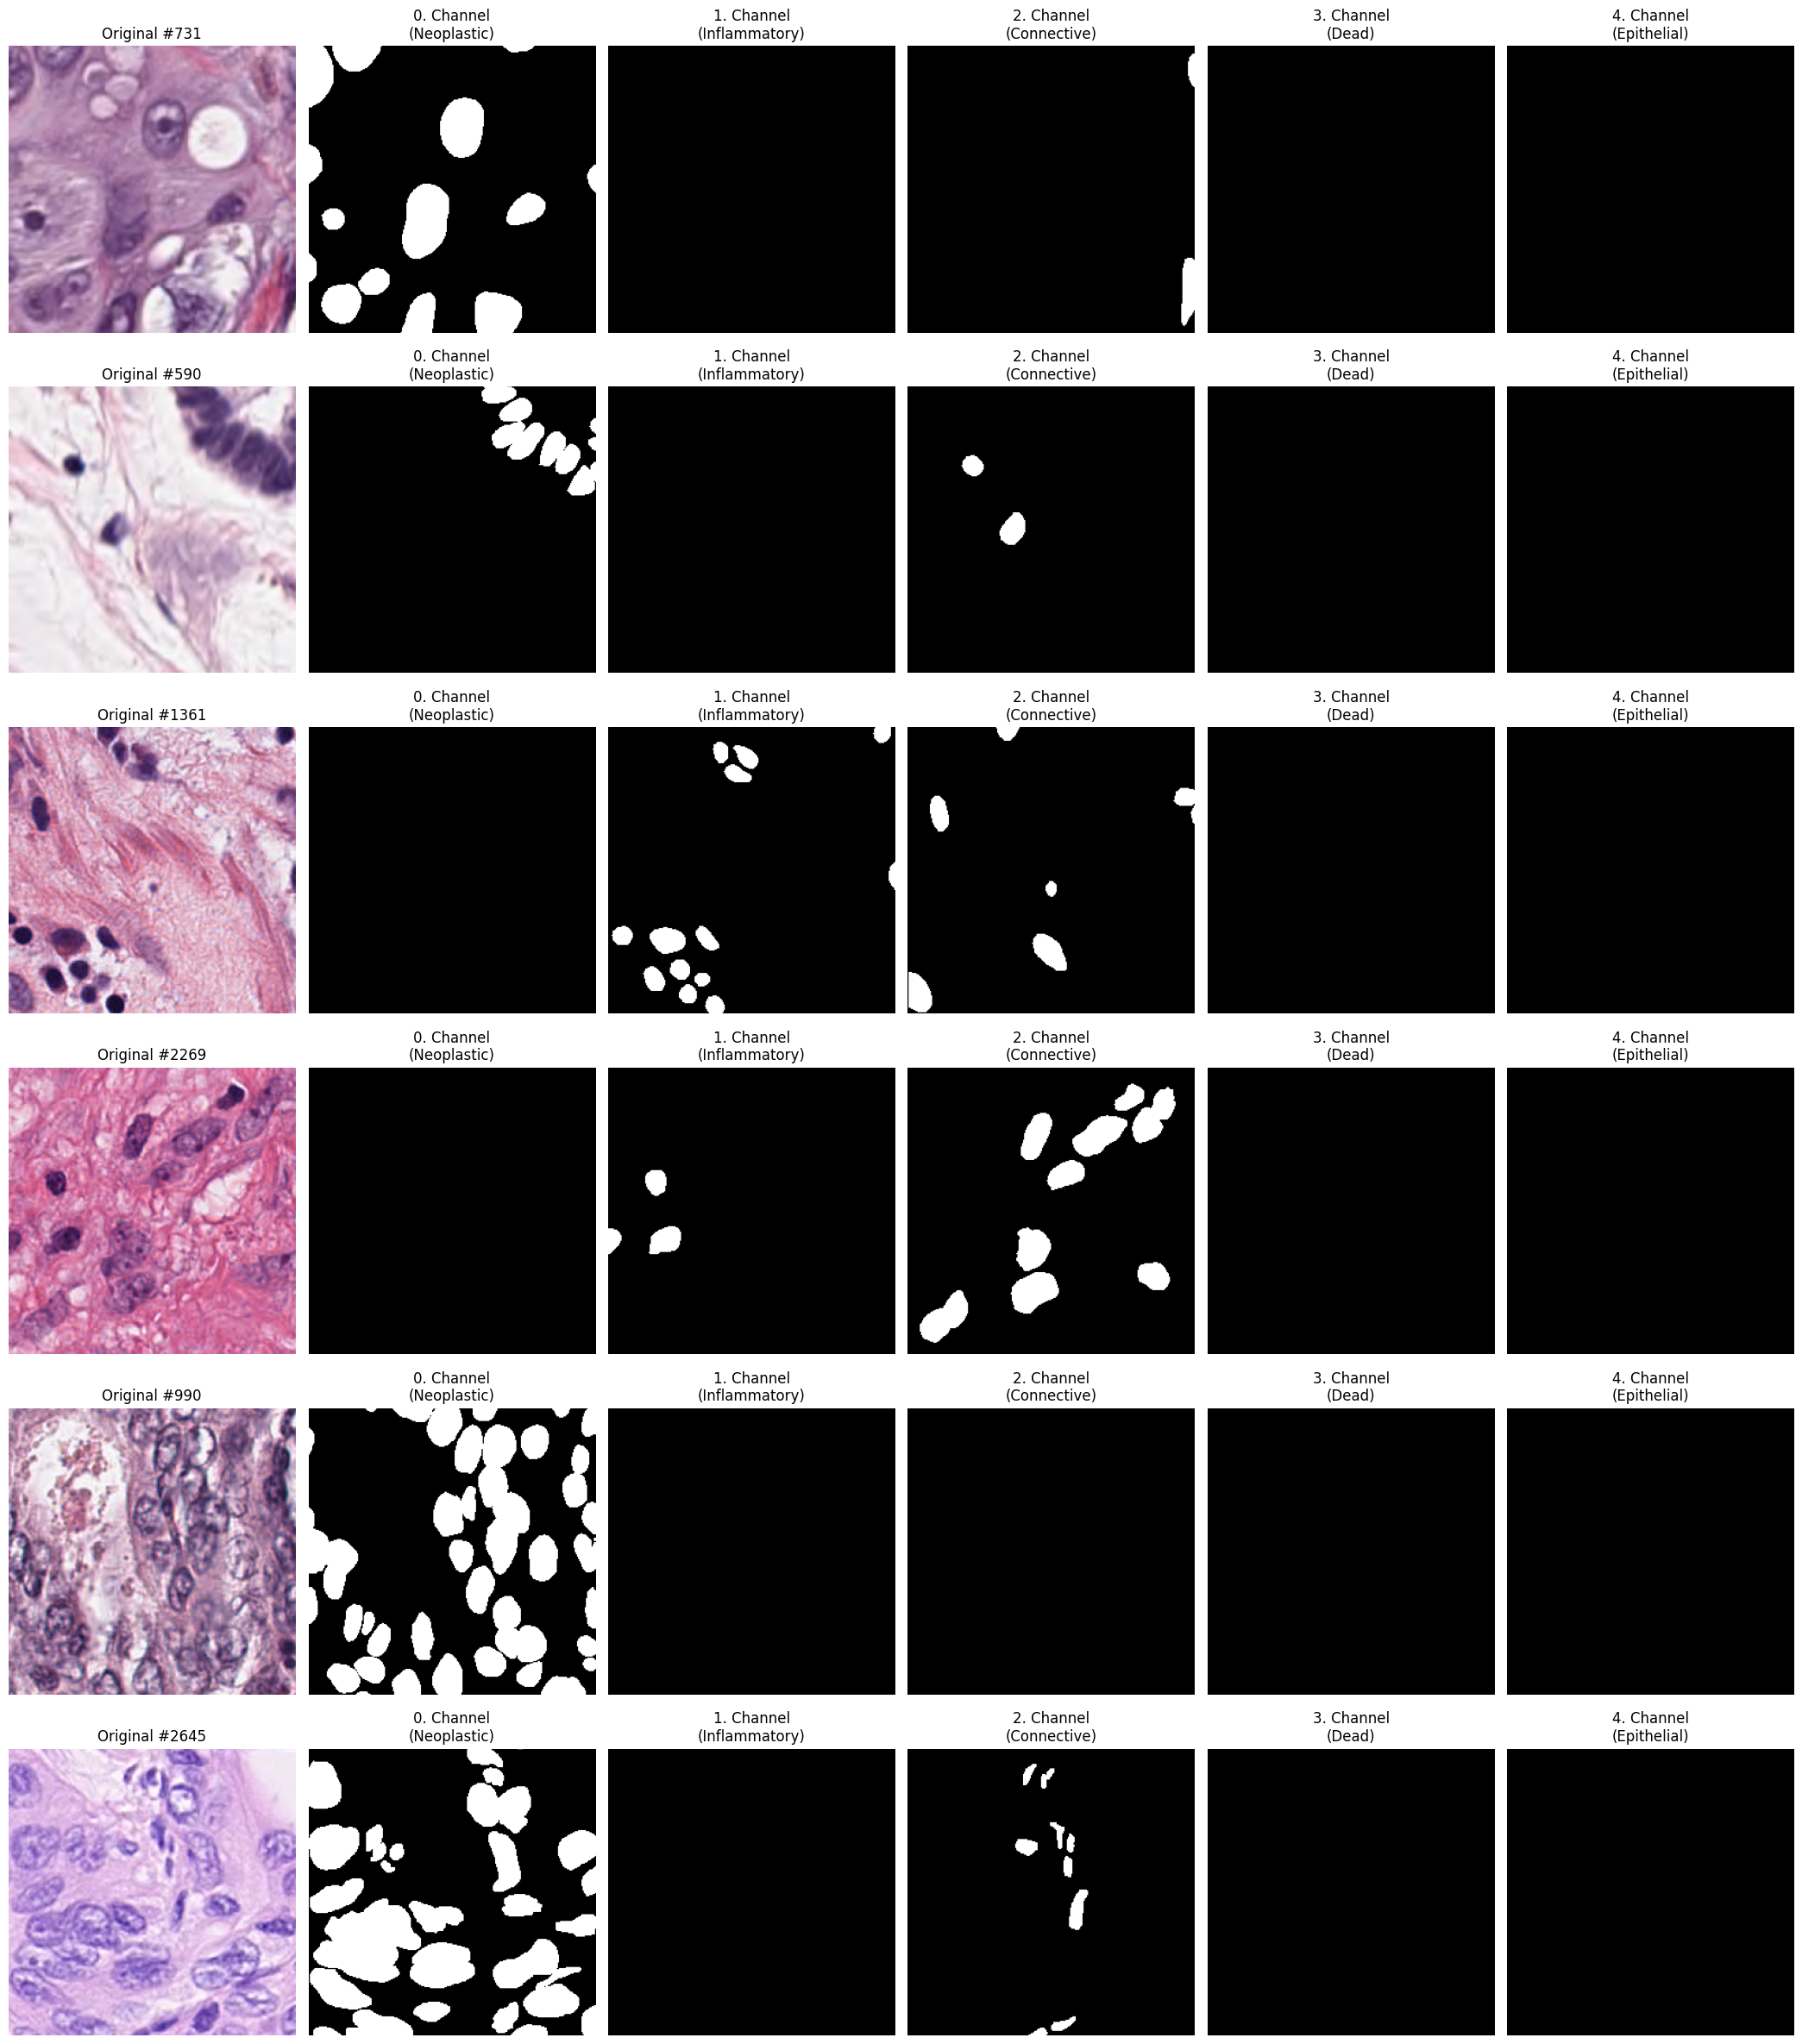

In [4]:
# category names for the 5 non-background mask channels
categories_plot = ["Neoplastic", "Inflammatory", "Connective", "Dead", "Epithelial"]

# pick 6 random sample indices to visualize
sample_idx = random.sample(range(images.shape[0]), 6)

# 6 rows (one per sample) x 6 columns (original image + 5 category channels)
fig, axes = plt.subplots(6, 6, figsize=(21, 24))

for row, idx in enumerate(sample_idx):
    # first column: the original image
    axes[row, 0].imshow(images[idx].astype(np.uint8))
    axes[row, 0].set_title(f"Original #{idx}")
    axes[row, 0].axis("off")

    # remaining columns: one binary mask per category channel
    for ch in range(len(categories_plot)):
        axes[row, ch + 1].imshow(masks[idx, :, :, ch] > 0, cmap="gray")
        axes[row, ch + 1].set_title(f"{ch}. Channel\n({categories_plot[ch]})")
        axes[row, ch + 1].axis("off")

plt.tight_layout()
plt.show()